# Упражнение 3.5: медианный фильтр

Задача: считать черно-белое изображение с шумом «соль и перец», применить `cv2.medianBlur(source, ksize)` и восстановить двузначное число в левом верхнем углу.

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt

IMAGE_PATH = Path('input_images/blur_st-petersburg-russia-3747214_1280.jpg')
OUTPUT_DIR = Path('outputs')
OUTPUT_DIR.mkdir(exist_ok=True)

if not IMAGE_PATH.exists():
    raise FileNotFoundError(f'Не найден файл: {IMAGE_PATH}')

## 1. Чтение изображения

In [2]:
source = cv2.imread(str(IMAGE_PATH), cv2.IMREAD_GRAYSCALE)
if source is None:
    raise ValueError('OpenCV не смог считать изображение')

print(f'Размер изображения: {source.shape[1]}x{source.shape[0]}')
print(f'Диапазон интенсивностей: {source.min()}..{source.max()}')

Размер изображения: 1280x847
Диапазон интенсивностей: 0..255


## 2. Медианный фильтр и усиление контраста

Число находится в левой верхней части изображения. Для чтения удобно взять кроп и посмотреть несколько значений `ksize`.

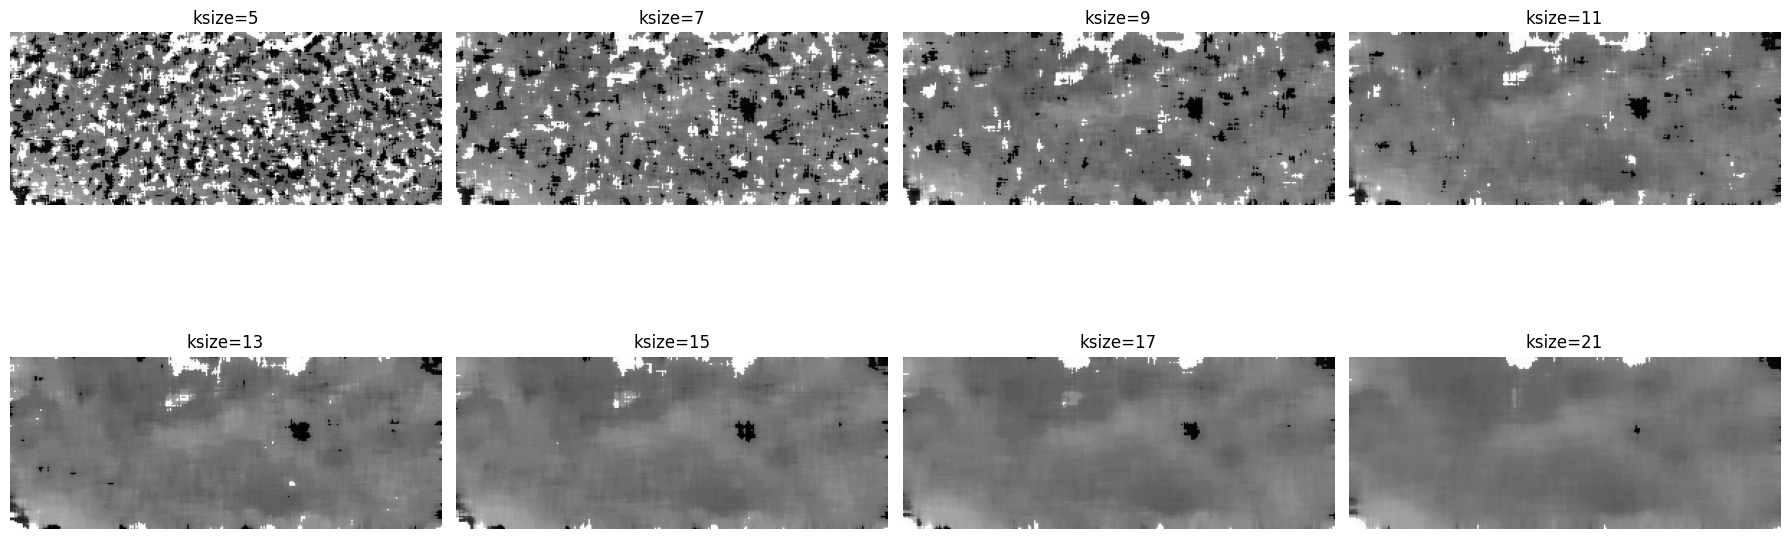

In [3]:
# Кроп с областью, где видно число.
x1, y1, x2, y2 = 0, 90, 300, 210
roi = source[y1:y2, x1:x2]

ksizes = [5, 7, 9, 11, 13, 15, 17, 21]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.ravel()

for ax, ksize in zip(axes, ksizes):
    filtered = cv2.medianBlur(roi, ksize)
    enhanced = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(4, 4)).apply(filtered)
    ax.imshow(enhanced, cmap='gray')
    ax.set_title(f'ksize={ksize}')
    ax.axis('off')

plt.tight_layout()
plt.show()

## 3. Дополнительная бинаризация

Адаптивный порог после медианного фильтра делает контуры цифр заметнее. На вариантах `ksize=13..21` читается число `88`.

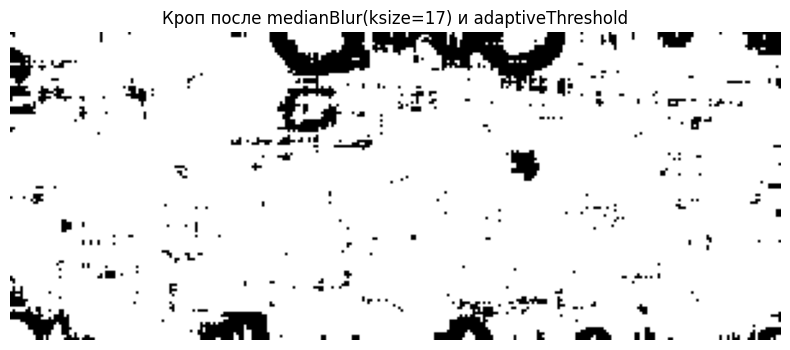

Ответ: 88


In [4]:
ksize = 17
filtered = cv2.medianBlur(roi, ksize)
binary = cv2.adaptiveThreshold(
    filtered,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    21,
    2,
)

cv2.imwrite(str(OUTPUT_DIR / 'number_88_median17_binary.png'), binary)

plt.figure(figsize=(10, 4))
plt.imshow(binary, cmap='gray')
plt.title('Кроп после medianBlur(ksize=17) и adaptiveThreshold')
plt.axis('off')
plt.show()

answer = 88
print(f'Ответ: {answer}')

## Ответ для формы

Полученное число: `88`